# Plot scientific interest for one pathogen–antibiotic pair

This notebook makes the same observed/predicted SI and publication-count plot used by `save_interesting_si_plots`, but for a pair you choose below. It uses the current saved yearly SI dataset, background counts, and SI configuration.

Change `PATHOGEN` and `ANTIBIOTIC` in the selection cell, then run the notebook. The example is *Mycobacterium tuberculosis*–Rifampicin.


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipeline_config import cfg, cfg_path, load_pipeline_config
from amr.pipelines.si import build_si_analysis_paths
from amr.si.core import plot_yearly_si_pair

PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)
ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level", "antibiotic")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANALYSIS_LEVEL)
SI_PATH = SI_PATHS["yearly_si"]
PATHOGEN_BACKGROUND_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BACKGROUND_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.figure_dir", PROJECT_ROOT) / "single_pair_si_plots"

if not SI_PATH.exists():
    raise FileNotFoundError(f"Missing {SI_PATH}. Run notebook 05_model_scientific_interest.ipynb first.")
si_df = pd.read_parquet(SI_PATH)
pathogen_background_df = pd.read_parquet(PATHOGEN_BACKGROUND_PATH)
antibiotic_background_df = pd.read_parquet(ANTIBIOTIC_BACKGROUND_PATH)
print(f"Loaded {len(si_df):,} yearly SI rows from {SI_PATH}")


Loaded 15,806 yearly SI rows from /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si.parquet


In [2]:
# Edit these two values to plot another pair.
PATHOGEN = "Mycobacterium tuberculosis"
ANTIBIOTIC = "Rifampicin"

# Resolve case-insensitively to the canonical spellings stored in the data.
pathogen_values = si_df["pathogen"].dropna().astype(str).unique()
antibiotic_values = si_df["antibiotic"].dropna().astype(str).unique()
pathogen_matches = [value for value in pathogen_values if value.casefold() == PATHOGEN.casefold()]
antibiotic_matches = [value for value in antibiotic_values if value.casefold() == ANTIBIOTIC.casefold()]
if not pathogen_matches:
    raise ValueError(f"Pathogen {PATHOGEN!r} is not present in {SI_PATH}.")
if not antibiotic_matches:
    raise ValueError(f"Antibiotic {ANTIBIOTIC!r} is not present in {SI_PATH}.")
PATHOGEN = pathogen_matches[0]
ANTIBIOTIC = antibiotic_matches[0]

pair_df = si_df.loc[
    si_df["pathogen"].eq(PATHOGEN) & si_df["antibiotic"].eq(ANTIBIOTIC)
].sort_values("year")
print(f"Pair: {PATHOGEN} — {ANTIBIOTIC}; yearly rows: {len(pair_df)}")
display(pair_df[["year", "count", "count_for_model", "SI"]].reset_index(drop=True))


Pair: Mycobacterium tuberculosis — Rifampicin; yearly rows: 27


,year,count,count_for_model,SI
0,2000,78,78.0,0.868144
1,2001,55,55.0,0.711083
2,2002,70,70.0,0.800930
3,2003,71,71.0,0.786582
4,2004,88,88.0,0.869211
5,2005,79,79.0,0.807771
6,2006,94,94.0,0.859588
7,2007,79,79.0,0.797159
8,2008,80,80.0,0.771200
9,2009,100,100.0,0.863747


Saved plot to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/single_pair_si_plots/Mycobacterium_tuberculosis__Rifampicin.pdf
Fit: 2000–2025; forecast extension: 5 years; valid training years: 26


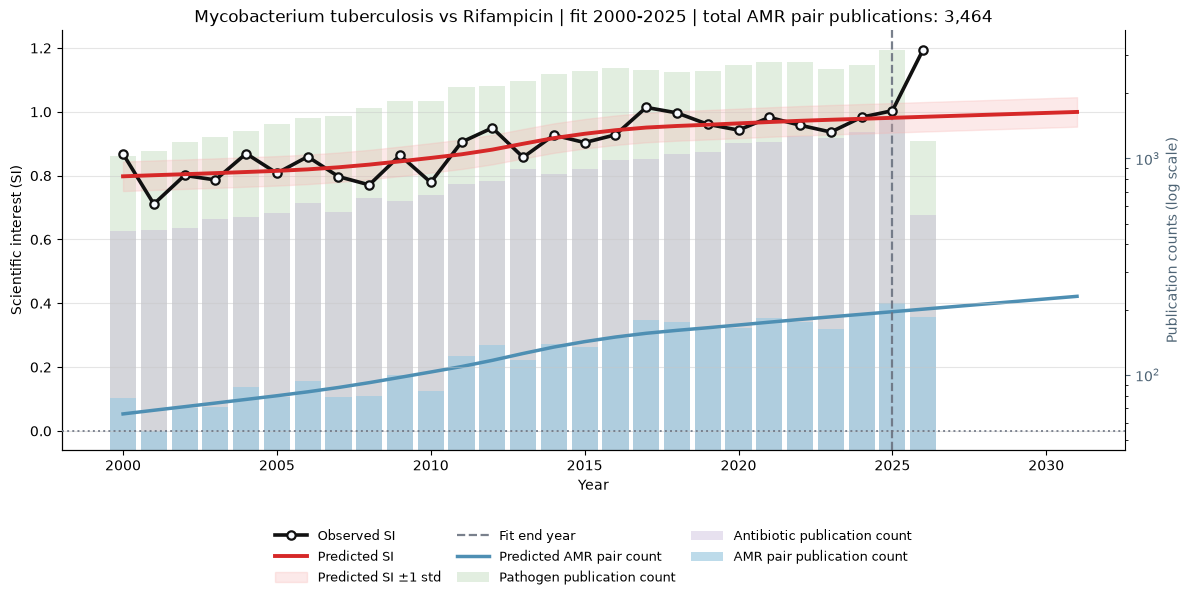

In [3]:
FIT_START_YEAR = int(cfg(PIPELINE_CONFIG, "si.fit_start_year"))
FIT_END_YEAR = int(cfg(PIPELINE_CONFIG, "si.curve_fit_end_year"))
NUM_FUTURE_YEARS = int(cfg(PIPELINE_CONFIG, "si.num_future_years"))
MIN_AMR_PAIR_PUBLICATION_COUNT = float(cfg(PIPELINE_CONFIG, "si.min_amr_pair_publication_count"))
MIN_NUM_YEARS_WITH_VALID_COUNTS = int(cfg(PIPELINE_CONFIG, "si.min_num_years_with_valid_counts"))
LOESS_FRAC = float(cfg(PIPELINE_CONFIG, "si.loess_frac"))
LOESS_DEGREE = int(cfg(PIPELINE_CONFIG, "si.loess_degree"))
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = bool(cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero"))

plot_result = plot_yearly_si_pair(
    si_df=si_df,
    pathogen=PATHOGEN,
    antibiotic=ANTIBIOTIC,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_additional_years=NUM_FUTURE_YEARS,
    loess_frac=LOESS_FRAC,
    loess_degree=LOESS_DEGREE,
    tail_damping_years=TAIL_DAMPING_YEARS,
    min_amr_pair_publication_count=MIN_AMR_PAIR_PUBLICATION_COUNT,
    min_num_years_with_valid_counts=MIN_NUM_YEARS_WITH_VALID_COUNTS,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    pathogen_background_df=pathogen_background_df,
    antibiotic_background_df=antibiotic_background_df,
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
def _plot_slug(value):
    return str(value).strip().replace("/", "_").replace("\\", "_").replace(" ", "_").replace(":", "_")

output_path = OUTPUT_DIR / f"{_plot_slug(PATHOGEN)}__{_plot_slug(ANTIBIOTIC)}.pdf"
plot_result["figure"].savefig(output_path, bbox_inches="tight")
print(f"Saved plot to {output_path}")
print(
    f"Fit: {FIT_START_YEAR}–{FIT_END_YEAR}; forecast extension: {NUM_FUTURE_YEARS} years; "
    f"valid training years: {plot_result['train_df']['year'].nunique()}"
)
display(plot_result["figure"])
import matplotlib.pyplot as plt
plt.close(plot_result["figure"])
